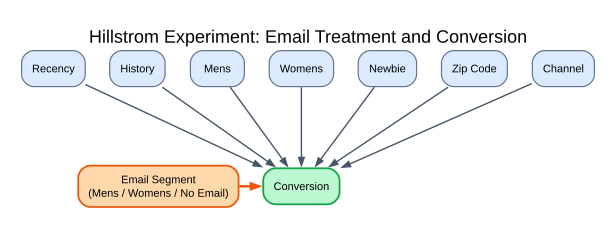

In [ ]:
from IPython.display import display
import pandas as pd
from dowhy import CausalModel
from graphviz import Source
import os

os.environ["PATH"] += os.pathsep + r"C:/Program Files/Graphviz/bin"

df = pd.read_csv("../Data/Processed/train.csv")

causal_graph = r"""
digraph {
    graph [
        rankdir=TB,
        bgcolor="white",
        pad=0.3,
        nodesep=0.35,
        ranksep=1.1,
        splines=true,
        outputorder=edgesfirst,
        label="Hillstrom Experiment: Email Treatment and Conversion",
        labelloc=t,
        fontsize=18,
        fontname="Arial"
    ];

    node [
        shape=box,
        style="rounded,filled",
        fontname="Arial",
        fontsize=11,
        color="#64748b",
        penwidth=1.2,
        margin="0.15,0.10"
    ];

    edge [
        color="#475569",
        penwidth=1.4,
        arrowsize=0.8
    ];

    recency [label="Recency", fillcolor="#DBEAFE"];
    history [label="History", fillcolor="#DBEAFE"];
    mens [label="Mens", fillcolor="#DBEAFE"];
    womens [label="Womens", fillcolor="#DBEAFE"];
    newbie [label="Newbie", fillcolor="#DBEAFE"];
    zip_code [label="Zip Code", fillcolor="#DBEAFE"];
    channel [label="Channel", fillcolor="#DBEAFE"];

    segment [
        label="Email Segment\n(Mens / Womens / No Email)",
        fillcolor="#FED7AA",
        color="#EA580C",
        penwidth=1.8
    ];

    conversion [
        label="Conversion",
        fillcolor="#BBF7D0",
        color="#16A34A",
        penwidth=1.8
    ];

    { rank=same; recency; history; mens; womens;
      newbie; zip_code; channel; }

    { rank=same; segment; conversion; }

    recency -> history -> mens -> womens -> newbie
        -> zip_code -> channel [style=invis, weight=15];

    recency -> conversion;
    history -> conversion;
    mens -> conversion;
    womens -> conversion;
    newbie -> conversion;
    zip_code -> conversion;
    channel -> conversion;

    segment -> conversion [
        color="#EA580C",
        penwidth=2.5
    ];
}
"""

model = CausalModel(
    data=df,
    treatment="segment",
    outcome="conversion",
    graph=causal_graph
)

os.makedirs("../Reports/figures", exist_ok=True)

Source(causal_graph).render(
    filename="../Reports/figures/causal_dag",
    format="png",
    cleanup=True,
    view=True
)

display(Source(causal_graph))

In [6]:
import networkx as nx

# Compatibility fix for DoWhy with NetworkX 3.5+
nx.algorithms.d_separated = nx.algorithms.d_separation.is_d_separator

In [8]:

mens_df = df[df["segment"].isin(["Mens E-Mail", "No E-Mail"])].copy()
mens_df["mens_treatment"] = (mens_df["segment"] == "Mens E-Mail").astype(int)

graph_mens = """
digraph {
    mens_treatment -> conversion;
}
"""

model_mens = CausalModel(
    data=mens_df,
    treatment="mens_treatment",
    outcome="conversion",
    graph=graph_mens
)

mens_estimand = model_mens.identify_effect()
print("Mens vs No E-Mail:")
print(mens_estimand)


womens_df = df[df["segment"].isin(["Womens E-Mail", "No E-Mail"])].copy()
womens_df["womens_treatment"] = (womens_df["segment"] == "Womens E-Mail").astype(int)

graph_womens = """
digraph {
    womens_treatment -> conversion;
}
"""

model_womens = CausalModel(
    data=womens_df,
    treatment="womens_treatment",
    outcome="conversion",
    graph=graph_womens
)

womens_estimand = model_womens.identify_effect()
print("\nWomens vs No E-Mail:")
print(womens_estimand)


Mens vs No E-Mail:
Estimand type: nonparametric-ate

### Estimand : 1
Estimand name: backdoor
Estimand expression:
       d                       
────────────────(E[conversion])
d[mensₜᵣₑₐₜₘₑₙₜ]               
Estimand assumption 1, Unconfoundedness: If U→{mens_treatment} and U→conversion then P(conversion|mens_treatment,,U) = P(conversion|mens_treatment,)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!


Womens vs No E-Mail:
Estimand type: nonparametric-ate

### Estimand : 1
Estimand name: backdoor
Estimand expression:
        d                        
──────────────────(E[conversion])
d[womensₜᵣₑₐₜₘₑₙₜ]               
Estimand assumption 1, Unconfoundedness: If U→{womens_treatment} and U→conversion then P(conversion|womens_treatment,,U) = P(conversion|womens_treatment,)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found